# I. Importing the needed packages for the prediction

In this notebook we will do a data analysis on how AI affects the students on their education.

In [15]:
#Math and Data Analysis packages
import pandas as pd
import numpy as np

#Data Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

#Machine Learning Models
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

#for warnings
import warnings
warnings.filterwarnings("ignore")

In [23]:
df = pd.read_csv('ai_student_impact_dataset (1).csv')
df.head(15)

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium
5,100006,STEM,Junior,3.449,6.50,Debugging/Troubleshooting,Beginner,1,False,14.19,4,Allowed_With_Citation,5,3.666,65.92,High
6,100007,STEM,Freshman,3.622,31.41,Summarizing_Reading,Advanced,5,True,13.11,8,Allowed_With_Citation,7,4.000,67.97,Medium
7,100008,Arts,Junior,2.746,5.33,Copywriting/Drafting,Intermediate,3,False,18.45,2,Actively_Encouraged,1,2.965,85.09,Medium
8,100009,Business,Sophomore,3.420,2.00,Debugging/Troubleshooting,Beginner,2,True,2.87,1,Strict_Ban,5,3.396,55.71,Medium
9,100010,Business,Sophomore,3.046,19.99,Debugging/Troubleshooting,Intermediate,2,True,12.49,3,Strict_Ban,8,2.978,87.18,High


# AI Usage and Student Impact Analysis

## Objective

This notebook explores how the use of Generative AI may relate to student academic performance, skill retention, anxiety, study behavior, and burnout risk.

The analysis includes:

- Data inspection and cleaning
- Exploratory Data Analysis (EDA)
- Feature preparation
- Classification modeling
- Model evaluation
- Interpretation of important predictors

### Main Prediction Task

The primary machine learning objective is to predict a student's **Burnout Risk Level**:

- Low
- Medium
- High

This is a multiclass classification problem.

In [20]:
for col in df.columns:
    print(f"----------- {col} -----------")
    print(df[col].unique())

----------- Student_ID -----------
[100001 100002 100003 ... 149998 149999 150000]
----------- Major_Category -----------
['Humanities' 'Medical' 'Business' 'STEM' 'Arts']
----------- Year_of_Study -----------
['Senior' 'Junior' 'Freshman' 'Sophomore' 'Graduate']
----------- Pre_Semester_GPA -----------
[2.418 3.821 3.398 ... 1.688 1.467 2.027]
----------- Weekly_GenAI_Hours -----------
[23.31  1.12 21.26 ... 32.09 35.33 29.82]
----------- Primary_Use_Case -----------
['Copywriting/Drafting' 'Ideation' 'Summarizing_Reading'
 'Debugging/Troubleshooting' 'Direct_Answer_Generation']
----------- Prompt_Engineering_Skill -----------
['Beginner' 'Advanced' 'Intermediate']
----------- Tool_Diversity -----------
[1 5 2 4 3]
----------- Paid_Subscription -----------
[ True False]
----------- Traditional_Study_Hours -----------
[ 8.13 16.65 10.35 ... 24.36 26.87 28.92]
----------- Perceived_AI_Dependency -----------
[ 5  3  2  4  8  1  6  7 10  9]
----------- Institutional_Policy -----------
['A

In [27]:
for i in df.columns:
    print (i)

Student_ID
Major_Category
Year_of_Study
Pre_Semester_GPA
Weekly_GenAI_Hours
Primary_Use_Case
Prompt_Engineering_Skill
Tool_Diversity
Paid_Subscription
Traditional_Study_Hours
Perceived_AI_Dependency
Institutional_Policy
Anxiety_Level_During_Exams
Post_Semester_GPA
Skill_Retention_Score
Burnout_Risk_Level


## Initial Data Inspection

Before performing analysis or machine learning, the dataset is checked for:

- Data types
- Missing values
- Duplicate records
- Invalid or unusual values
- Unique categorical values

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  object 
 2   Year_of_Study               50000 non-null  object 
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  object 
 6   Prompt_Engineering_Skill    50000 non-null  object 
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  object 
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           500

In [29]:
df.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


In [31]:
df.describe(include="object")

,Major_Category,Year_of_Study,Primary_Use_Case,Prompt_Engineering_Skill,Institutional_Policy,Burnout_Risk_Level
count,50000,50000,50000,50000,50000,50000
unique,5,5,5,3,3,3
top,STEM,Junior,Debugging/Troubleshooting,Beginner,Allowed_With_Citation,Medium
freq,15059,11045,12295,18495,25224,21144


# Check missing Values

In [32]:
df.isnull().sum()

Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64

### Missing Values

No missing values were detected in the dataset. Therefore, no missing-value imputation was required.

# Check Duplicate Rows

In [33]:
df.duplicated().sum()

np.int64(0)

### Duplicate Records

No completely duplicated rows were found in the dataset.

# Check Unique Values
Especially important for categorical columns.

In [36]:
categorical_columns = df.select_dtypes(include=["object","bool"]).columns

for column in categorical_columns:
    print ("\n",column)
    print (df[column].value_counts())


 Major_Category
Major_Category
STEM          15059
Business      12538
Humanities     9994
Medical        6476
Arts           5933
Name: count, dtype: int64

 Year_of_Study
Year_of_Study
Junior       11045
Freshman     11031
Senior       10634
Sophomore     9860
Graduate      7430
Name: count, dtype: int64

 Primary_Use_Case
Primary_Use_Case
Debugging/Troubleshooting    12295
Copywriting/Drafting         12011
Ideation                     10721
Summarizing_Reading           8633
Direct_Answer_Generation      6340
Name: count, dtype: int64

 Prompt_Engineering_Skill
Prompt_Engineering_Skill
Beginner        18495
Intermediate    17696
Advanced        13809
Name: count, dtype: int64

 Paid_Subscription
Paid_Subscription
False    28846
True     21154
Name: count, dtype: int64

 Institutional_Policy
Institutional_Policy
Allowed_With_Citation    25224
Actively_Encouraged      14988
Strict_Ban                9788
Name: count, dtype: int64

 Burnout_Risk_Level
Burnout_Risk_Level
Medium    211

Apparently the data already looks standardized so predictive modelling will be very easy.

## Removing Non-Predictive Identifiers

`Student_ID` uniquely identifies each student but does not describe a behavioral or academic characteristic.

Including identifiers in a machine learning model may introduce meaningless patterns and does not improve generalization.

Therefore, `Student_ID` is removed from the modeling dataset.

In [37]:
df_clean = df.drop(columns=["Student_ID"]).copy()
df_clean.head()

,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


## Numerical Range Validation

Numerical variables were inspected to identify impossible or suspicious values such as negative study hours, invalid GPA values, or scores outside their expected ranges.

In [41]:
numeric_columns = df_clean.select_dtypes(include=np.number).columns

df_clean[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Pre_Semester_GPA,50000.0,3.146102,0.478854,1.183,2.83400,3.210,3.521,3.998
Weekly_GenAI_Hours,50000.0,8.427752,8.269490,0.000,2.39000,5.800,11.720,40.000
Tool_Diversity,50000.0,2.800260,1.188020,1.000,2.00000,3.000,4.000,5.000
Traditional_Study_Hours,50000.0,11.209271,5.156426,1.000,7.56000,11.180,14.710,35.860
Perceived_AI_Dependency,50000.0,3.505360,1.820812,1.000,2.00000,3.000,5.000,10.000
Anxiety_Level_During_Exams,50000.0,4.270760,2.144066,1.000,3.00000,4.000,6.000,10.000
Post_Semester_GPA,50000.0,3.349299,0.495673,1.000,3.02375,3.421,3.749,4.000
Skill_Retention_Score,50000.0,75.798125,13.281626,10.780,66.82000,76.000,85.190,100.000


## Detect Outliers

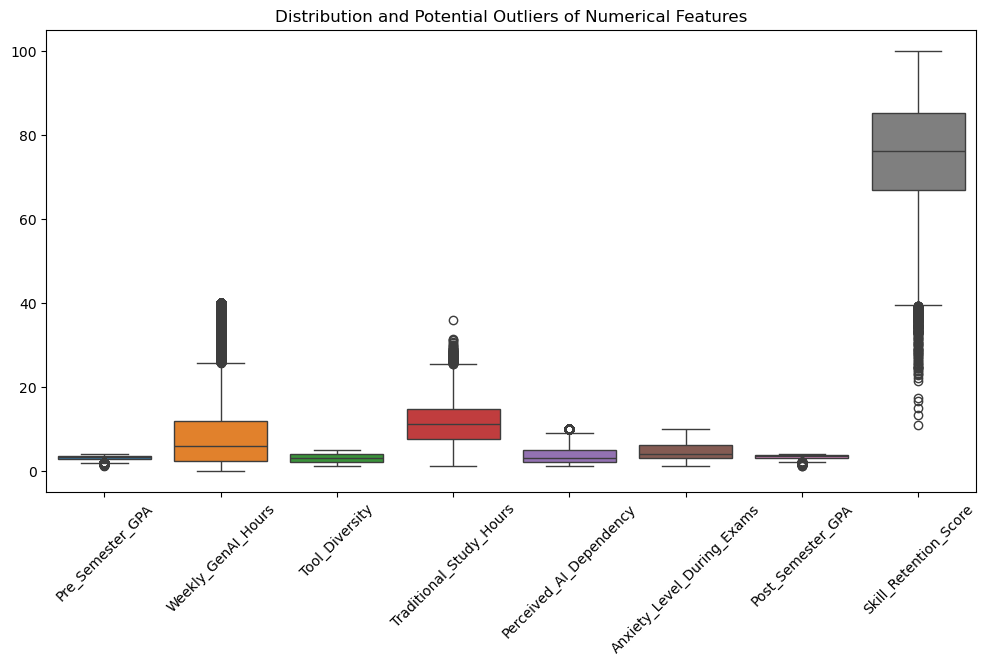

In [42]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_clean[numeric_columns])
plt.xticks(rotation=45)
plt.title("Distribution and Potential Outliers of Numerical Features")
plt.show()

### Outlier Assessment

Potential outliers were inspected using boxplots.

Outliers were not automatically removed because extreme observations can represent valid student behavior. For example, students with unusually high AI usage or study hours may still represent legitimate cases.

Outliers should only be removed when there is evidence that they resulted from data-entry or measurement errors.

# EDA: Target Variable

# Exploratory Data Analysis

## Burnout Risk Distribution

The distribution of the target variable is examined to determine whether the classes are balanced.

In [43]:
df_clean["Burnout_Risk_Level"].value_counts()

Burnout_Risk_Level
Medium    21144
Low       16369
High      12487
Name: count, dtype: int64

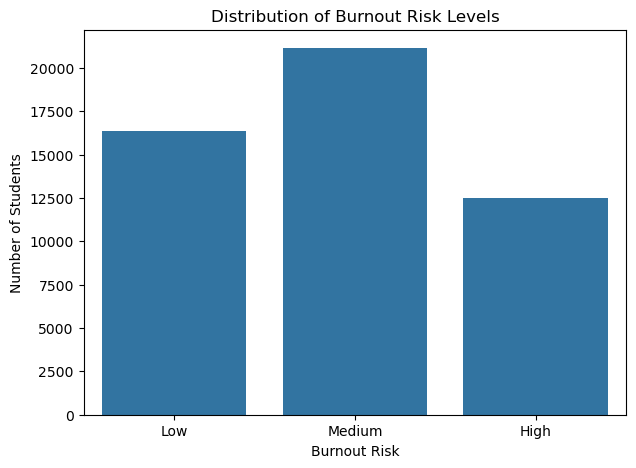

In [44]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Burnout_Risk_Level",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Burnout Risk Levels")
plt.xlabel("Burnout Risk")
plt.ylabel("Number of Students")
plt.show()

In [45]:
burnout_distribution = (
    df_clean["Burnout_Risk_Level"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

burnout_distribution

Burnout_Risk_Level
Medium    42.29
Low       32.74
High      24.97
Name: proportion, dtype: float64

## Generative AI Usage

The distribution of weekly Generative AI usage is examined to understand how frequently students use AI tools.

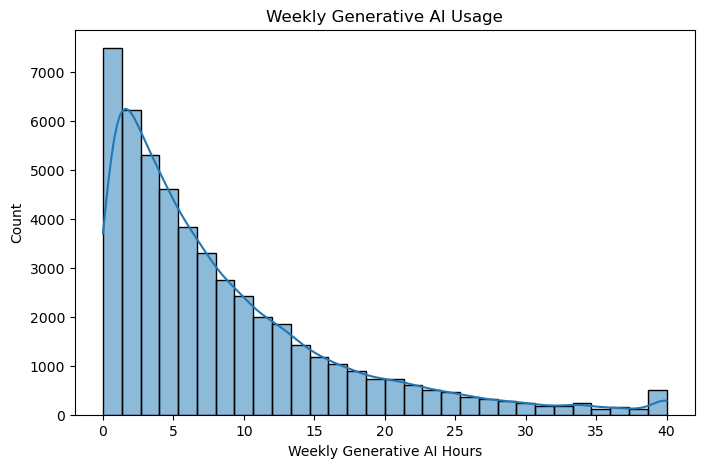

In [46]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Weekly_GenAI_Hours",
    bins=30,
    kde=True
)

plt.title("Weekly Generative AI Usage")
plt.xlabel("Weekly Generative AI Hours")
plt.show()

## AI Usage vs Burnout

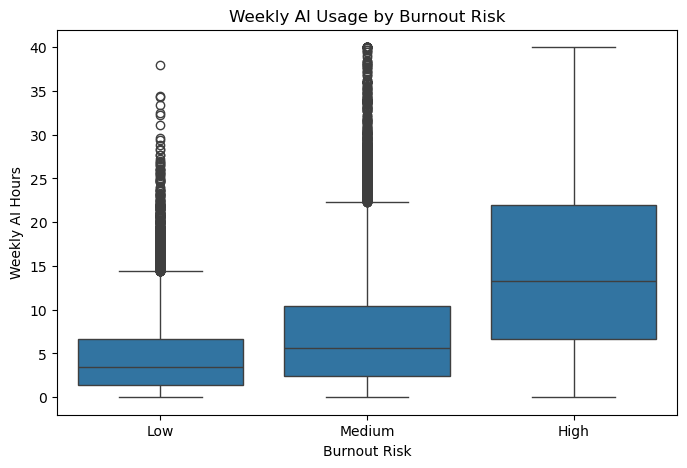

In [47]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Burnout_Risk_Level",
    y="Weekly_GenAI_Hours",
    order=["Low", "Medium", "High"]
)

plt.title("Weekly AI Usage by Burnout Risk")
plt.xlabel("Burnout Risk")
plt.ylabel("Weekly AI Hours")
plt.show()

# Anxiety vs Burnout

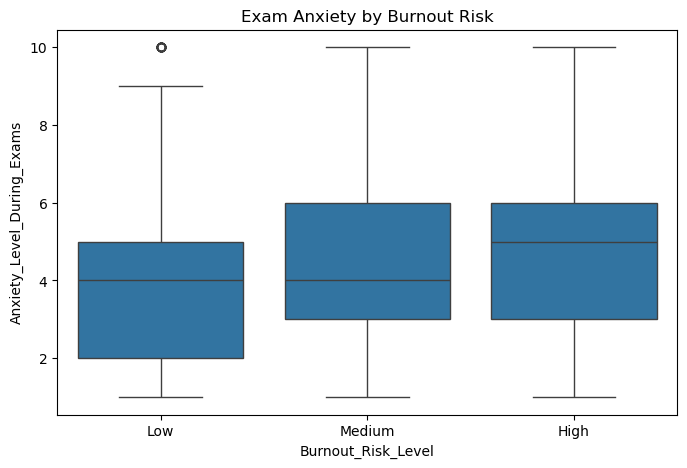

In [48]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Burnout_Risk_Level",
    y="Anxiety_Level_During_Exams",
    order=["Low", "Medium", "High"]
)

plt.title("Exam Anxiety by Burnout Risk")
plt.show()

## AI Dependency vs Burnout

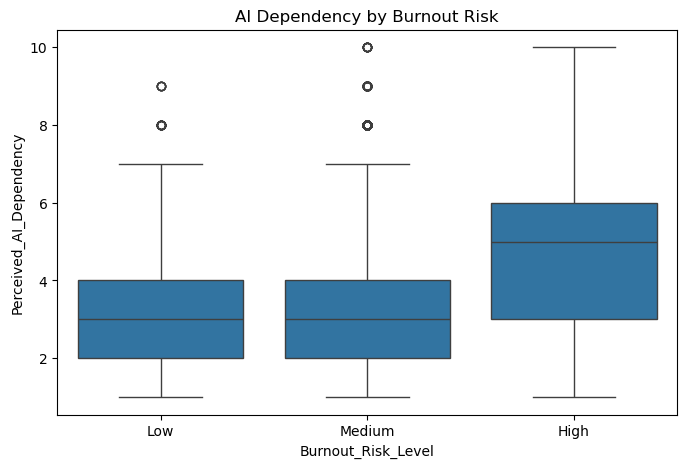

In [49]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Burnout_Risk_Level",
    y="Perceived_AI_Dependency",
    order=["Low", "Medium", "High"]
)

plt.title("AI Dependency by Burnout Risk")
plt.show()

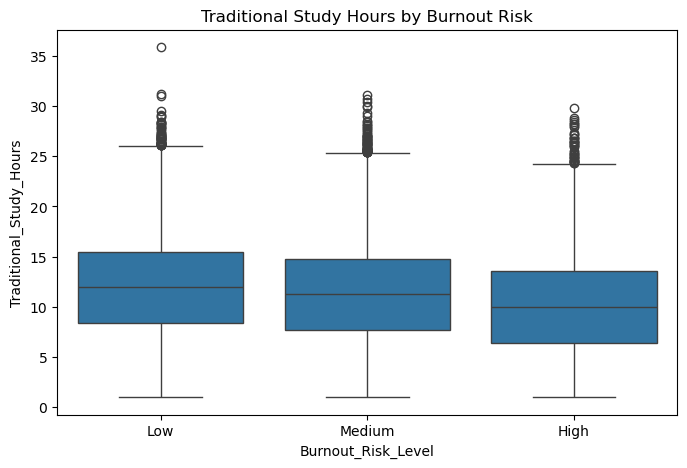

In [50]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Burnout_Risk_Level",
    y="Traditional_Study_Hours",
    order=["Low", "Medium", "High"]
)

plt.title("Traditional Study Hours by Burnout Risk")
plt.show()

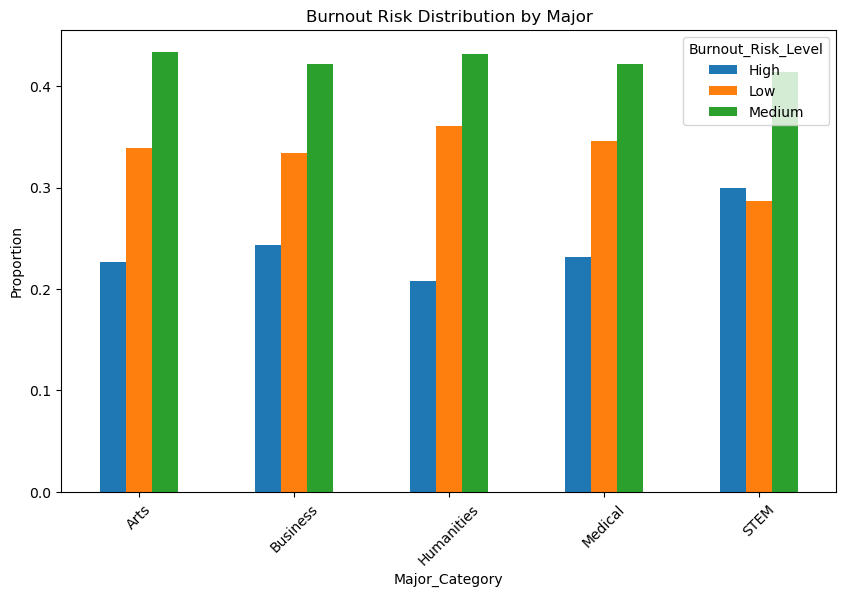

In [51]:
pd.crosstab(
    df_clean["Major_Category"],
    df_clean["Burnout_Risk_Level"],
    normalize="index"
).plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Burnout Risk Distribution by Major")
plt.ylabel("Proportion")
plt.xticks(rotation=45)
plt.show()

## Correlation Analysis

A correlation matrix is used to identify linear relationships between numerical variables.

Correlation does not imply causation, but it can help identify potentially important relationships between variables.

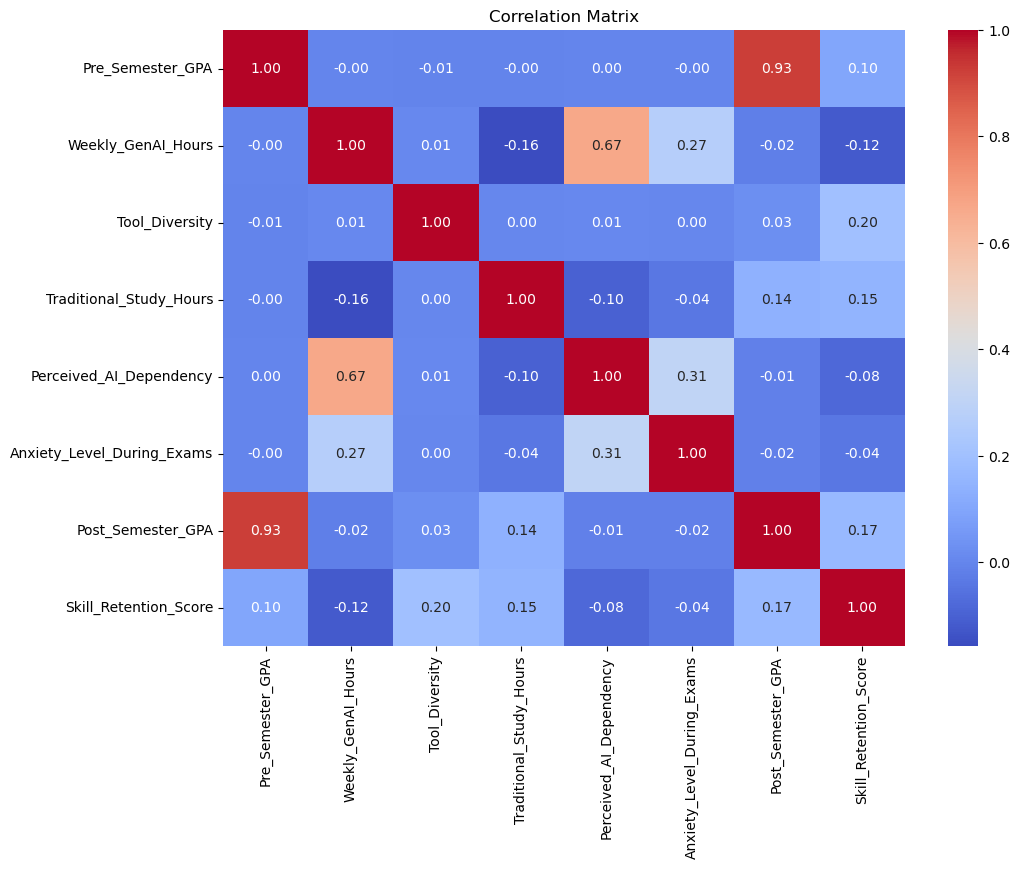

In [52]:
numeric_df = df_clean.select_dtypes(include=np.number)

plt.figure(figsize=(11, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

In [53]:
df_clean["GPA_Change"] = (
    df_clean["Post_Semester_GPA"] -
    df_clean["Pre_Semester_GPA"]
)

df_clean["GPA_Change"].describe()

count    50000.000000
mean         0.203197
std          0.187192
min         -0.924000
25%          0.087000
50%          0.204000
75%          0.325000
max          1.008000
Name: GPA_Change, dtype: float64

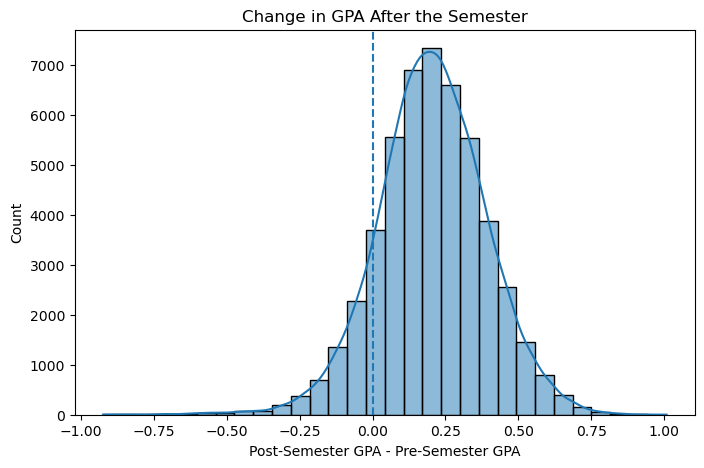

In [54]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="GPA_Change",
    bins=30,
    kde=True
)

plt.axvline(0, linestyle="--")

plt.title("Change in GPA After the Semester")
plt.xlabel("Post-Semester GPA - Pre-Semester GPA")
plt.show()

# Machine Learning Problem

## Research Question

Can student burnout risk be predicted using academic background, study habits, Generative AI usage behavior, AI dependency, and exam anxiety?

The target variable is:

`Burnout_Risk_Level`

Possible classes:

- Low
- Medium
- High

Because the target contains three categories, the problem is treated as a **multiclass classification task**.

In [55]:
features = [
    "Major_Category",
    "Year_of_Study",
    "Pre_Semester_GPA",
    "Weekly_GenAI_Hours",
    "Primary_Use_Case",
    "Prompt_Engineering_Skill",
    "Tool_Diversity",
    "Paid_Subscription",
    "Traditional_Study_Hours",
    "Perceived_AI_Dependency",
    "Institutional_Policy",
    "Anxiety_Level_During_Exams"
]

In [56]:
X = df_clean[features]
y = df_clean["Burnout_Risk_Level"]

## Train-Test Split

The dataset is divided into training and testing sets.

- 80% of the dataset is used for model training.
- 20% is reserved for testing.

Stratified sampling is used to maintain approximately the same burnout-risk distribution in both datasets.

In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (40000, 12)
Testing shape: (10000, 12)


In [58]:
categorical_features = X.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical:")
print(categorical_features)

print("\nNumerical:")
print(numerical_features)

Categorical:
['Major_Category', 'Year_of_Study', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Paid_Subscription', 'Institutional_Policy']

Numerical:
['Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Tool_Diversity', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams']


## Data Preprocessing

The dataset contains both numerical and categorical variables.

Categorical features are converted into machine-readable form using **One-Hot Encoding**.

Numerical features are standardized so variables with larger numerical scales do not disproportionately influence models that are sensitive to feature scaling.

In [59]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

# Model 1: Multinomial Logistic Regression

Logistic Regression is used as a baseline classification model.

A baseline model provides a point of comparison for more complex machine learning algorithms.

In [60]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [61]:
logistic_predictions = logistic_model.predict(X_test)

In [62]:
print(
    "Accuracy:",
    accuracy_score(
        y_test,
        logistic_predictions
    )
)

print()

print(
    classification_report(
        y_test,
        logistic_predictions
    )
)

Accuracy: 0.5366

              precision    recall  f1-score   support

        High       0.67      0.47      0.55      2497
         Low       0.55      0.49      0.52      3274
      Medium       0.49      0.61      0.54      4229

    accuracy                           0.54     10000
   macro avg       0.57      0.52      0.54     10000
weighted avg       0.55      0.54      0.54     10000



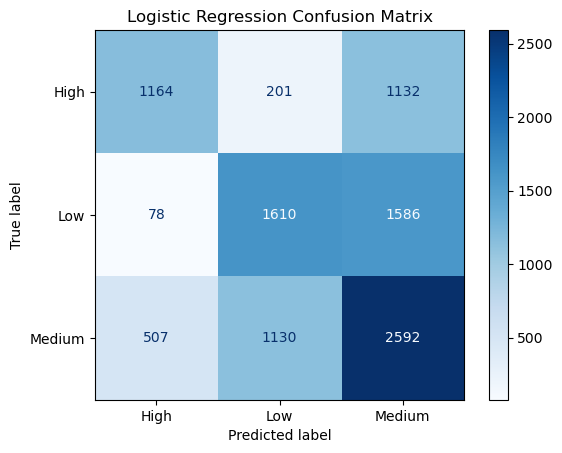

In [63]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

# Model 2: Random Forest Classifier

Random Forest combines multiple decision trees to produce more stable predictions.

It is useful because it:

- Handles nonlinear relationships
- Can model interactions between variables
- Is relatively resistant to overfitting compared with a single decision tree
- Can provide feature-importance estimates

In [64]:
random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [65]:
rf_predictions = random_forest.predict(X_test)

In [66]:
print(
    "Accuracy:",
    accuracy_score(
        y_test,
        rf_predictions
    )
)

print()

print(
    classification_report(
        y_test,
        rf_predictions
    )
)

Accuracy: 0.5172

              precision    recall  f1-score   support

        High       0.65      0.47      0.54      2497
         Low       0.51      0.47      0.49      3274
      Medium       0.48      0.59      0.52      4229

    accuracy                           0.52     10000
   macro avg       0.55      0.51      0.52     10000
weighted avg       0.53      0.52      0.52     10000



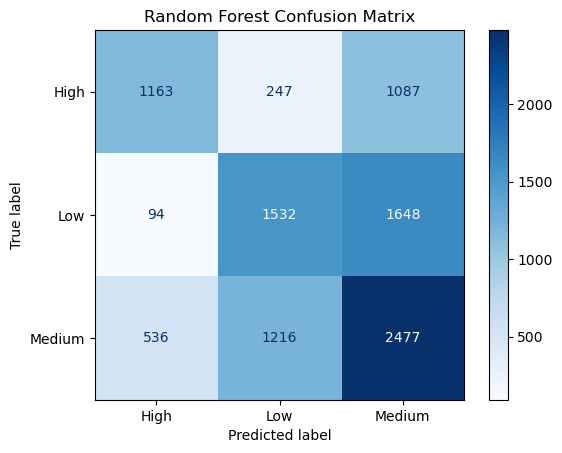

In [67]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

# Model Comparison

The models are compared using classification accuracy.

However, accuracy should not be used alone. Precision, recall, and F1-score are also considered because they provide information about how well each burnout-risk category is identified.

In [68]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(
            y_test,
            logistic_predictions
        ),
        accuracy_score(
            y_test,
            rf_predictions
        )
    ]
})

results.sort_values(
    "Accuracy",
    ascending=False
)

,Model,Accuracy
0,Logistic Regression,0.5366
1,Random Forest,0.5172


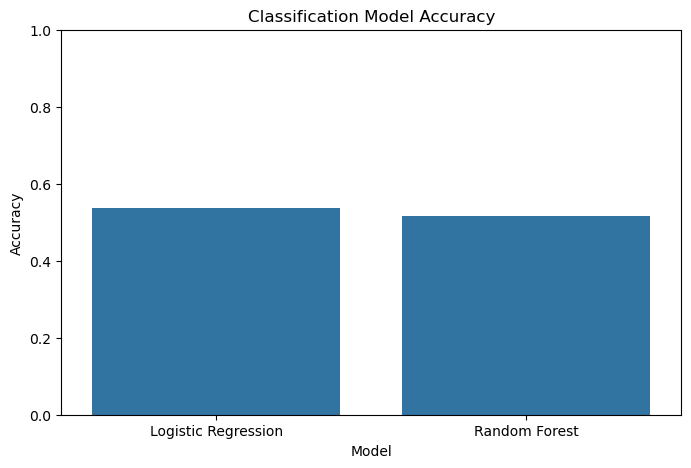

In [69]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1)

plt.title("Classification Model Accuracy")
plt.ylabel("Accuracy")
plt.show()

In [70]:
preprocessor_fitted = (
    random_forest
    .named_steps["preprocessor"]
)

feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

importances = (
    random_forest
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
)

feature_importance.head(15)

,Feature,Importance
1,num__Weekly_GenAI_Hours,0.208534
0,num__Pre_Semester_GPA,0.137709
3,num__Traditional_Study_Hours,0.135182
4,num__Perceived_AI_Dependency,0.079066
5,num__Anxiety_Level_During_Exams,0.077397
2,num__Tool_Diversity,0.056292
23,cat__Prompt_Engineering_Skill_Intermediate,0.017645
27,cat__Institutional_Policy_Allowed_With_Citation,0.016256
22,cat__Prompt_Engineering_Skill_Beginner,0.016247
16,cat__Primary_Use_Case_Copywriting/Drafting,0.015958


## Evaluation Metrics

### Accuracy

Accuracy measures the percentage of all predictions that were classified correctly.

### Precision

Precision measures how often predictions for a particular burnout level were actually correct.

For example, high precision for the `High` burnout class means that when the model predicts that a student has high burnout risk, that prediction is usually correct.

### Recall

Recall measures how many actual cases of a burnout level were successfully identified.

For burnout prediction, recall can be particularly important because failing to identify students who truly have high burnout risk may be undesirable.

### F1-Score

The F1-score balances precision and recall.

It is useful when evaluating models where both false positives and false negatives are important.

In [71]:
sample_student = pd.DataFrame({
    "Major_Category": ["STEM"],
    "Year_of_Study": ["Junior"],
    "Pre_Semester_GPA": [3.2],
    "Weekly_GenAI_Hours": [15],
    "Primary_Use_Case": ["Debugging/Troubleshooting"],
    "Prompt_Engineering_Skill": ["Intermediate"],
    "Tool_Diversity": [4],
    "Paid_Subscription": [True],
    "Traditional_Study_Hours": [10],
    "Perceived_AI_Dependency": [7],
    "Institutional_Policy": ["Allowed_With_Citation"],
    "Anxiety_Level_During_Exams": [8]
})

prediction = random_forest.predict(
    sample_student
)

prediction

array(['Medium'], dtype=object)

In [72]:
probabilities = (
    random_forest
    .predict_proba(
        sample_student
    )
)

probability_df = pd.DataFrame(
    probabilities,
    columns=random_forest
    .named_steps["classifier"]
    .classes_
)

probability_df

,High,Low,Medium
0,0.346667,0.303333,0.35


# Overall Findings

The dataset contained 50,000 student records describing academic background, Generative AI usage, traditional study habits, AI dependency, anxiety, academic outcomes, and burnout risk.

Initial data inspection showed that the dataset contained no missing values or duplicate records. Student ID was excluded from modeling because it serves only as an identifier and does not provide meaningful predictive information.

Exploratory analysis was performed to investigate relationships between Generative AI use, academic performance, study behavior, anxiety, AI dependency, and burnout risk.

For the machine learning component, student burnout risk was treated as a multiclass classification problem with three possible outcomes: Low, Medium, and High.

Logistic Regression was used as a baseline model, while Random Forest was used to capture more complex and nonlinear relationships between student characteristics.

The models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices. Feature-importance analysis was also performed to identify which student characteristics contributed most strongly to the Random Forest predictions.

The results demonstrate how machine learning can be used not only to describe existing patterns in student behavior but also to estimate burnout-risk categories for previously unseen student records.

# Conclusion

This analysis demonstrated a complete data science workflow, beginning with data validation and exploratory analysis and ending with machine learning classification.

The dataset was suitable for analysis because it contained no missing records or duplicate observations. Categorical variables were encoded, numerical variables were standardized where appropriate, and the dataset was divided into training and testing subsets.

Two classification algorithms were evaluated: Logistic Regression and Random Forest. Their performances were compared using multiple classification metrics rather than relying only on accuracy.

The machine learning analysis also allowed the most influential predictors of burnout risk to be identified. These findings can provide insight into which student behaviors and academic characteristics are most strongly associated with the model's burnout-risk predictions.

Future work could examine additional algorithms, hyperparameter tuning, cross-validation, and alternative prediction targets such as academic performance or skill retention.